This notebook analyses and cleans the handwriting data in the `iamondb` and `deepwriting` datasets.

Both datasets come from the [DeepWriting](https://github.com/emreaksan/deepwriting) project ([paper](https://arxiv.org/abs/1801.08379)) and use the same JSON format, but they hold different handwriting:

- `iamondb` is the DeepWriting authors' character-segmented export of [IAM-OnDB](https://fki.tic.heia-fr.ch/databases/iam-on-line-handwriting-database). It holds 200 of IAM-OnDB's 221 writers (21 were dropped for low-quality samples or missing annotations), written on a whiteboard. The coordinates are raw, unnormalised whiteboard units.
- `deepwriting` is new data the DeepWriting authors collected from 94 writers on an iPad Pro, copying the same IAM-OnDB text lines. It is raw too: the authors' pre-processed release is a separate set of `.npz` files.

The two datasets share text but no writers or ink. Their coordinates are in very different units (`iamondb`'s are roughly 6x larger), so distance thresholds in this notebook are measured relative to each sample's handwriting size.

In [1]:
from datetime import datetime
from itertools import pairwise
import json
import math
import pickle
from pathlib import Path
from typing import Any, Literal, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree
from scipy.stats import theilslopes
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Loading the Data

Your project should structure should be as follows:

```
.
├── data/
│   ├── raw/
│   │   ├── deepwriting/
│   │   └── iamondb/
│   └── cleaned/
├── checkpoints/
└── notebooks/
```

In [2]:
# Change this to your project root 

ROOT = Path("/Users/jacob/github.com/jda5/handwriting-synthesis")

In [3]:
DATA_DIR = ROOT / 'data'
RAW_DIR = DATA_DIR / 'raw'

DATASET: Literal['iamondb', 'deepwriting'] = 'deepwriting'

Each sample is composed of a sequence of points on an xy-coordinate grid. `x` and `y` are the pen coordinates in the capture device's raw units: whiteboard units for `iamondb` and screen pixels for `deepwriting`. The sequence of points are time-ordered. Consecutive points are about 10–20 ms apart in `iamondb`, and less regularly spaced in `deepwriting`.

`pen_up` is the pen state. `False` means the pen is pressed against the writing surface, `True` means it is lifted.

In [4]:
class Point(NamedTuple):
    x: float
    y: float
    pen_up: bool

In [5]:
# A function the converts a list of JSON encoded sampled pen positions 
# to a list of Points and their corresponding target text.

def extract_sample(data: dict[str, Any]) -> tuple[str, list[Point]]:
    for sample in data.values():
        if 'word_stroke' not in sample:
            continue

        # ev is the pen event type
            # 0 = pen down
            # 1 = pen move
            # 2 = pen up
        events = [int(point['ev']) for point in sample['word_stroke']]

        points = []

        for point, event, next_event in zip(sample['word_stroke'], events, events[1:] + [0]):

            # Not every stroke ends with a pen up event: single-point strokes (dots) and some
            # strokes run straight into the next pen down. So the pen also lifts before every
            # pen down, and at the end of the sample.
            pen_up = event == 2 or next_event == 0

            # Give a single-point stroke a pen down as well as a pen up, so that every stroke
            # starts with the pen pressed down
            if pen_up and event == 0:
                points.append(Point(float(point['x']), float(point['y']), False))

            points.append(Point(float(point['x']), float(point['y']), pen_up))

        yield sample['word_ascii'], points

In [6]:
# Loads a series of files, extracts each sample's Points and target text
# to fashion a dataset

def load_files(files: map) -> tuple[list[str], list[list[Point]]]:
    samples = []
    texts = []

    for filepath in files:
        with open(filepath) as f:
            data = json.load(f)

        for sample_text, sample_points in extract_sample(data):
            texts.append(sample_text)
            samples.append(sample_points)

    return texts, samples

In [7]:
# Function that loads an entire dataset. Attempts to load from a cache, before calling
# load_files on all JSON files in the iamondb or deepwriting sub-directories

def load_dataset(dataset: Literal['iamondb', 'deepwriting']) -> tuple[list[str], list[list[Point]]]:

    pickle_filepath = RAW_DIR / f"{dataset}-dataset.pkl"

    if pickle_filepath.is_file():
        with open(pickle_filepath, "rb") as f:
            texts, samples = pickle.load(f)
    else:
        texts, samples = load_files((RAW_DIR / dataset).glob("**/*.json"))
    
        with open(pickle_filepath, "wb") as f:
            pickle.dump((texts, samples), f)

    return samples, texts

In [10]:
samples, texts = load_dataset(DATASET)

Let's first remove all duplicates before we visualise or transform the data, so that we get an accurate depiction of the data.

In [11]:
# Hashes the points in each sample and weeds out duplicates samples

def remove_duplicates(samples: list[list[Point]], texts: list[str]):
    unique_samples, unique_texts = [], []

    seen = set()
    
    for points, target in zip(samples, texts):
        hashable_sample = tuple(points)
        
        if hashable_sample in seen:
            continue

        unique_samples.append(points)
        unique_texts.append(target)
        
        seen.add(hashable_sample)
        
    print(f"Removed {len(samples) - len(unique_samples)} duplicate samples.")
    return unique_samples, unique_texts

In [12]:
samples, texts = remove_duplicates(samples, texts)

Removed 1118 duplicate samples.


# Data Transformations

Rather than feeding the model raw points we give it _pen strokes_. These are the `dx` (delta x) and `dy` offsets from the previous point in the sequence. The model then attempts to predict what the next `dx` and `dy` in the sequence is (aka. where will the pen move to next from the current point).

Furthermore, we additionally give the model a one-hot encoding of `pen_up`, `pen_down` and `finished`, which generally makes it a bit easier to predict what state the pen is in using Categorical Cross Entropy (see https://research.google/pubs/a-neural-representation-of-sketch-drawings/)

In [13]:
# End of sequence token that models "finished writing"

eos_token = (0, 0, 0, 0, 1)

In [14]:
# A function that turns a list of Points to a list of strokes (dx, dy offsets)
# as well as a one-hot encoding of the pen state

# Returns a numpy array of shape (N, 5) where N is the number of Points in the sample

def calculate_strokes(points: list[Point], include_eos: bool = True) -> np.ndarray:
    
    strokes = []
    prev_x, prev_y = None, None

    for point in points:

        # Calculate offsets - initialize to 0 for the first point
        dx = 0 if prev_x is None else point.x - prev_x
        dy = 0 if prev_y is None else point.y - prev_y

        # samples are mapped to:
        # [dx, dy, pen_down, pen_up, finished]
        # The last three being one-hot encoded
        strokes.append((dx, dy, not point.pen_up, point.pen_up, 0))

        prev_x, prev_y = point.x, point.y

    if include_eos:
        strokes.append(eos_token)

    return np.array(strokes, dtype=np.float32)

In [15]:
# Shifts pen point sequences horizontally and vertical so the 
# overall leftmost coordinate sits at x = 0 and the overall topmost coordinate
# sits at y = 0.

def normalize_points(points: list[Point]) -> list[Point]:

    min_x = float('inf')
    min_y = float('inf')

    for point in points:
        min_x = min(min_x, point.x)
        min_y = min(min_y, point.y)

    return [
        Point(p.x - min_x, p.y - min_y, p.pen_up) for p in points
    ]

In [68]:
samples = [normalize_points(sample) for sample in samples]
strokes = [calculate_strokes(sample) for sample in samples]

The two datasets record coordinates in very different units: `iamondb`'s whiteboard units are roughly 6x larger than `deepwriting`'s screen pixels, and writers vary in size too. So rather than using fixed distances, every threshold in this notebook is a multiple of a sample's _handwriting scale_: the interquartile range of the points' heights about a robust baseline, which tracks how big the letters are.

In [17]:
# Robust baseline: a Theil-Sen line through each piece's median point, so a handful of
# far-away artifacts can't tilt it the way they tilt a least-squares fit

def fit_baseline(coords: list[np.ndarray]) -> tuple[float, float]:
    centres = np.array([np.median(c, axis=0) for c in coords])
    if len(centres) > 2:
        slope, offset = theilslopes(centres[:, 1], centres[:, 0])[:2]
    else:
        slope, offset = 0.0, np.median(centres[:, 1])

    return slope, offset


# The size of a sample's handwriting in its own units: the interquartile range of how far
# each point sits above/below the baseline through its strokes

def handwriting_scale(points: list[Point]) -> float:
    strokes, current = [], []

    for point in points:
        current.append(point)

        if point.pen_up:
            strokes.append(np.array([(p.x, p.y) for p in current]))
            current = []

    if current:
        strokes.append(np.array([(p.x, p.y) for p in current]))

    slope, offset = fit_baseline(strokes)
    heights = np.concatenate([c[:, 1] - (slope * c[:, 0] + offset) for c in strokes])
    q1, q3 = np.percentile(heights, [25, 75])

    return q3 - q1

In [18]:
scales = [handwriting_scale(sample) for sample in samples]

print("Median handwriting scale:", np.median(scales))

Median handwriting scale: 16.58911568651088


# Data Visualisations

The following section are a series of functions that help us inspect and understand the data better. These functions work for both `iamondb` and `deepwriting` datasets, though have primarily been used on the `deepwriting` dataset.

In [19]:
# Functions that draws the pen strokes allowing us visualise a sample

def draw_strokes(strokes: np.ndarray, label=None):

    # Isolate where the pen lifts
    stroke_end_indices = np.argwhere(strokes[:, 2] == 0)[:, 0]

    # Cumsum reconstructs the absolute coordinates from the dx/dy offsets
    coordinates = strokes[:, :2].cumsum(axis=0)
    strokes = np.split(coordinates, stroke_end_indices + 1)

    # Spawn a figure with a wide aspect ratio suited for handwriting
    plt.figure(figsize=(12, 3))

    # Plot the invisible pen-up movements (jumps) in faint yellow
    plt.plot(coordinates[:, 0], -coordinates[:, 1], "y:", alpha=0.4)

    # Plot the actual pen-down strokes - ignore EOS
    for stroke in strokes[:-1]:
        if len(stroke) > 0:
            plt.plot(stroke[:, 0], -stroke[:, 1], ".-", color="black")

    if label:
        plt.title(label)

    plt.axis("off")
    plt.tight_layout()
    plt.show()


def draw_points(points: list[Point], label: str | None = None):
    draw_strokes(calculate_strokes(points, include_eos=False), label=label)

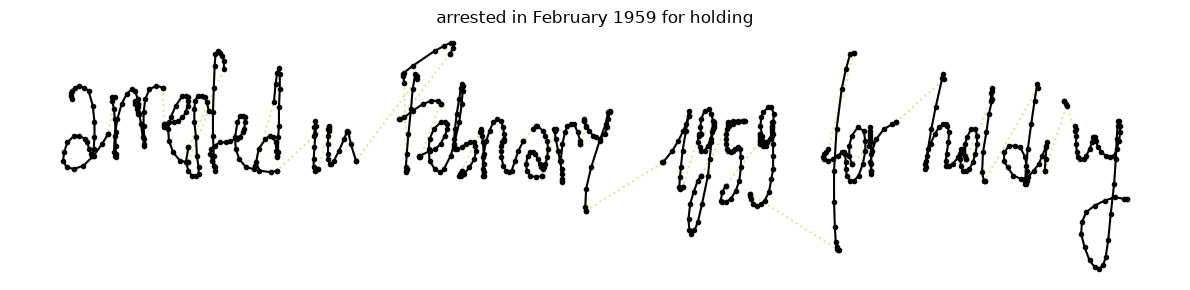

In [20]:
SAMPLE_INDEX = 10

draw_points(samples[SAMPLE_INDEX], texts[SAMPLE_INDEX])

Let's first get a sense of the length of the samples, some averages, as well as how many samples we have to work with.

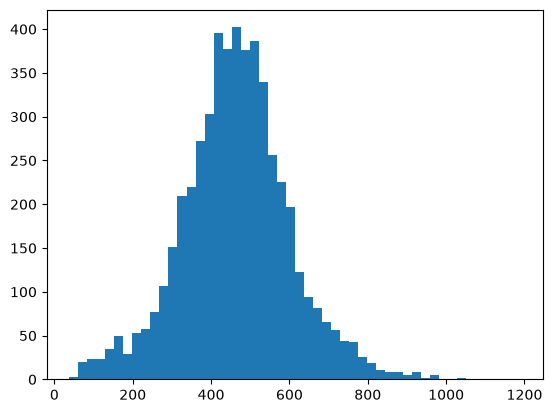

In [21]:
# View the lengths of the samples (number of points in a sample)

sample_lengths = [len(sample) for sample in samples]

plt.hist(sample_lengths, bins=50)
plt.show()

In [22]:
# Get the mean, max and min sample length

from statistics import mean

print("Number of Samples:", len(samples))
print("Mean Sample Length:", mean(sample_lengths))
print("Max Length:", max(sample_lengths))
print("Min Length:", min(sample_lengths))

Number of Samples: 5192
Mean Sample Length: 463.93721109399075
Max Length: 1189
Min Length: 38


We will use a character-level embedding in the (encoder) model. Let's see how many characters are represented in the dataset.

In [23]:
alphabet = set()
for text in texts:
    for char in text:
        alphabet.add(char)

print("Character count:", len(alphabet))

Character count: 79


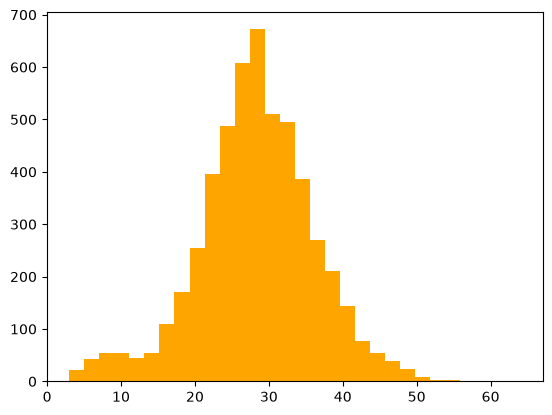

In [24]:
# View the lengths of the texts (number of characters in each target)

text_lengths = [len(text) for text in texts]

plt.hist(text_lengths, bins=30, color="orange")
plt.show()

Let's now look at the pen strokes (the `dx` and `dy` offsets between Points in a sample)

In [25]:
# Gather all offsets into a list, measured in handwriting-scale units so that
# both datasets are comparable

dx, dy = [], []

for sequences, scale in zip(strokes, scales):
    dx.extend(sequences[:,0] / scale)
    dy.extend(sequences[:,1] / scale)

dx, dy = np.array(dx), np.array(dy)

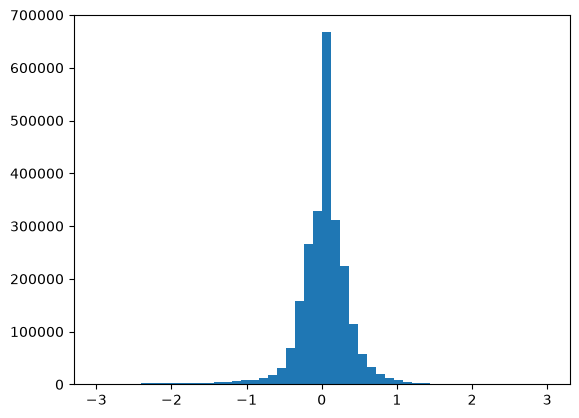

In [26]:
# View the horizontal / vertical stroke ranges

plt.hist(dy, bins=50, range=(-3, 3))
plt.show()

In [27]:
print("Mean dx:", mean(dx))
print("Max dx:", max(dx))

print("\nMean dy:", mean(dy))
print("Max dy:", max(dy))

Mean dx: 0.09884466949558587
Max dx: 57.66967862467889

Mean dy: 0.0016794313768358565
Max dy: 39.49764521193092


The vast majority of vertical (and horizontal) strokes fall into a range of about ±2.5 handwriting-scale units, yet there are quite a few that lie outside this range.

These are likely to be stroke outliers or artifacts.

In [28]:
# A function that flags a point as a likely outlier based on how far it 
# jumped from the previous point, in handwriting-scale units.

# The distance is Euclidean but weighted. In English we write left to right, 
# so large horizontal jumps are normal, while large vertical jumps are a 
# stronger sign of an outlier.

# The default threshold of 15 comes from manual inspection of deepwriting, where it was first
# picked as 250 raw units (one handwriting-scale unit is about 17 raw units there). Over 99% of
# consecutive points differ by less than 2.5 units in dx and dy, so anything beyond 15 is very
# likely an outlier.

def is_outlier(prev: Point, curr: Point, scale: float, threshold: float = 15.0):
    distance = math.hypot((curr.x - prev.x) * 0.75, (curr.y - prev.y) * 1.25) / scale
    return distance > threshold


# Gets the indices of samples that contain at least one outlier point.

def get_outlier_indexes(samples: list[list[Point]], scales: list[float]) -> list[int]:
    return [
        idx
        for idx, (sample, scale) in enumerate(zip(samples, scales))
        if any(is_outlier(prev, curr, scale) for prev, curr in pairwise(sample))
    ]

In [29]:
outlier_samples = get_outlier_indexes(samples, scales)

print(f"Found {len(outlier_samples)} samples with likely artifacts")

Found 509 samples with likely artifacts


Showing sample 125:


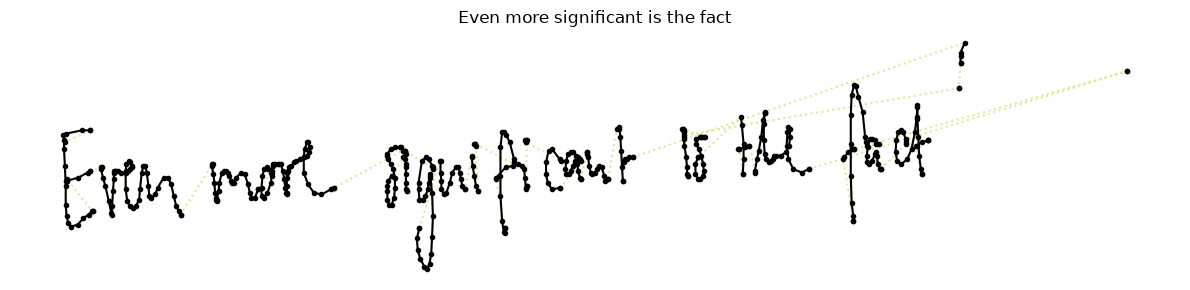

In [37]:
idx = outlier_samples[5]

print(f"Showing sample {idx}:")

draw_strokes(strokes[idx], label=texts[idx])

We can also see that many of these samples have artifcats at the start of their stroke sequence.

In [33]:
# Get the indicies of samples whose normalized starting point is far away from x = 0,
# in handwriting-scale units (6 units is about 100 raw units in deepwriting)

def get_start_artifact_indexes(
    samples: list[list[Point]], scales: list[float], threshold: float = 6.0
) -> list[int]:
    return [
        i for i, (points, scale) in enumerate(zip(samples, scales)) if points[0].x >= threshold * scale
    ]

In [34]:
start_artificat_samples = get_start_artifact_indexes(samples, scales)

print(f"Found {len(start_artificat_samples)} samples with likely start artifacts")

Found 271 samples with likely start artifacts


Showing sample 1114:


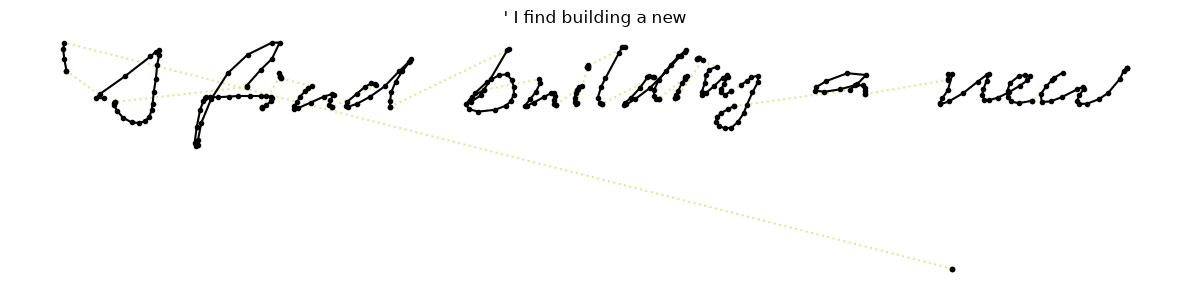

In [35]:
# iamondb has very few start artifacts, so fall back to the last one found

if start_artificat_samples:
    idx = start_artificat_samples[min(8, len(start_artificat_samples) - 1)]

    print(f"Showing sample {idx}:")

    draw_strokes(strokes[idx], label=texts[idx])

# Data Cleaning

There are several bits of cleaning we could. The first would be to remove artifacts from the Point sequences. Artifacts show up in two ways: stray strokes that sit well away from the line of handwriting, and pen-down "teleports" where the pen jumps further in a single 10–20 ms step than real handwriting can.

As with the diagnostics above, every distance is measured in handwriting-scale units, so the same settings work for both datasets.

Judging each point against the last point we kept doesn't work well: one stray point can become the reference that the next real stroke is "too far" from, and real handwriting gets deleted. Instead we judge whole strokes against the line of handwriting:

1. Split the sample into pieces at every pen lift and at every teleport.
2. Fit a robust baseline through the writing and allow a band of a few IQRs above and below it.
3. Keep genuine strokes that touch the band, keep teleport pieces only if they are substantial and on the line, and rescue marks that sit just above the line close to other ink (quotes, apostrophes, i-dots, T-bars).

One other bit of cleaning we can do is correct the global slant of a handwriting line (see: https://github.com/rudyoactiv/typescribe-handwriting/blob/master/handwriting_synthesis/drawing/operations.py#L44).

In [38]:
# Splits a sample into pieces at every pen lift, and also wherever the pen "teleports"
# while pressed down (a jump real handwriting can't make in 10-20 ms). Returns
# (piece, is_teleport) pairs, where is_teleport marks pieces that start or end at such a jump.

# max_step is in the sample's own units. Callers pass a multiple of its handwriting scale.

def split_strokes(points: list[Point], max_step: float) -> list[tuple[list[Point], bool]]:
    pieces = []
    current, teleport = [], False

    for point in points:
        if current and math.hypot(point.x - current[-1].x, point.y - current[-1].y) > max_step:
            pieces.append((current, True))
            current, teleport = [], True

        current.append(point)

        if point.pen_up:
            pieces.append((current, teleport))
            current, teleport = [], False

    if current:
        pieces.append((current, teleport))

    return pieces

In [39]:
# Removes artifacts a whole stroke at a time, and returns a new list of points with the
# artifacts filtered out. A stroke is judged by where it sits relative to the line of
# handwriting, rather than by how far it is from the last point we kept.

# max_step is in handwriting-scale units. The default of 5 sits far out in the tail of pen-down
# steps in both datasets: 99.9% of steps are under 1.7 units, and only a handful exceed 5.

def remove_artifacts(
    points: list[Point],
    max_step: float = 5.0,
    band_k: float = 3.0,
    near_k: float = 4.0,
    min_piece_points: int = 5,
) -> list[Point]:

    if not points:
        return []

    pieces = split_strokes(points, max_step * handwriting_scale(points))
    coords = [np.array([(p.x, p.y) for p in piece]) for piece, _ in pieces]

    slope, offset = fit_baseline(coords)

    # How far each point sits above/below the baseline, and an allowed band built from the IQR
    residuals = [c[:, 1] - (slope * c[:, 0] + offset) for c in coords]
    q1, q3 = np.percentile(np.concatenate(residuals), [25, 75])
    iqr = q3 - q1
    in_band = [(r >= q1 - band_k * iqr) & (r <= q3 + band_k * iqr) for r in residuals]

    # Genuine strokes (pen down -> pen up) that touch the band anchor everything else
    on_line = [mask.any() and not teleport for mask, (_, teleport) in zip(in_band, pieces)]
    if not any(on_line):
        return []
        
    anchors = cKDTree(np.concatenate([c for c, ok in zip(coords, on_line) if ok]))

    filtered_points: list[Point] = []

    for (piece, teleport), c, r, mask, ok in zip(pieces, coords, residuals, in_band, on_line):

        # Quotes, apostrophes, i-dots and T-bars sit above the band but close to other ink.
        # (y grows downwards, so "above" means a smaller residual)
        above_and_near = np.median(r) < q1 and anchors.query(c)[0].min() <= near_k * iqr

        if len(piece) < 2:
            # A lone point is a pen lift with no pen-down, which isn't a real stroke
            keep = False
        elif teleport:
            # A piece cut out by an impossible jump has to be substantial AND on the line
            keep = len(piece) >= min_piece_points and (mask.mean() >= 0.5 or above_and_near)
        else:
            # A genuine stroke is only dropped if it never comes near the line
            keep = ok or above_and_near

        if keep:
            # End every kept piece with a pen lift, so the jump to the next piece is a pen-up move
            filtered_points.extend(piece[:-1])
            filtered_points.append(piece[-1]._replace(pen_up=True))

    return filtered_points

Let's see the before / after of running the above function on a particular sample.

In [52]:
idx = 3461

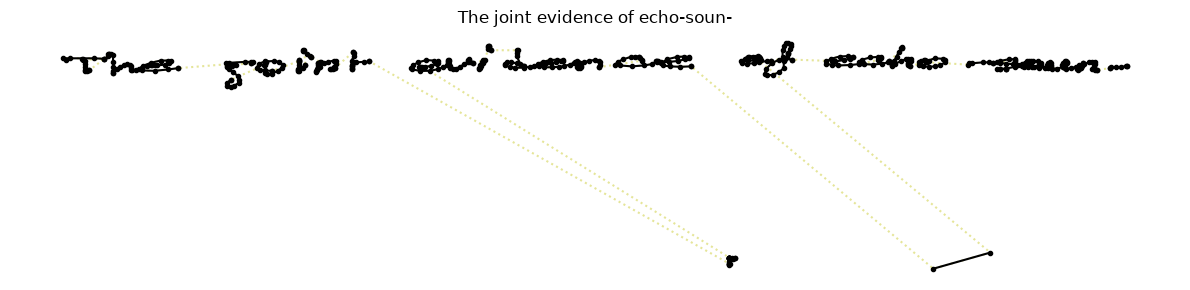

In [53]:
# before artifact removal

draw_points(samples[idx], label=texts[idx])

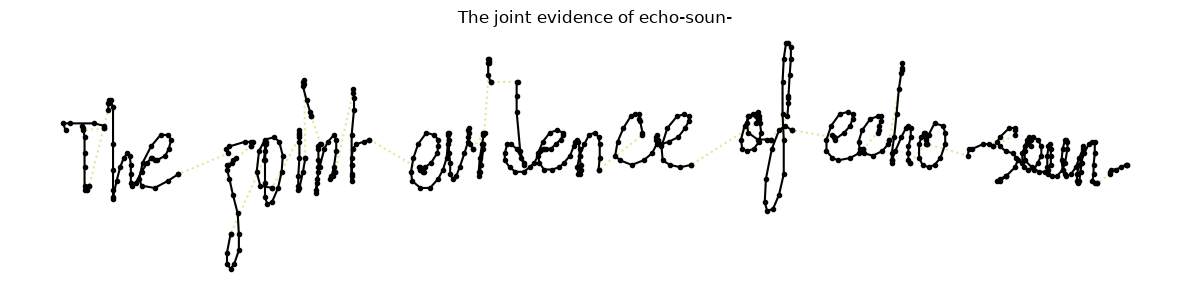

In [54]:
# after artifact removal

draw_points(remove_artifacts(samples[idx]), label=texts[idx])

Looks good 🎉

(Though the above example has a different problem; the sequence of strokes is either incomplete or truncated).

Let's apply this function to all samples and then look at how many points we removed from each.

In [46]:
scrubbed_samples = [remove_artifacts(points) for points in samples]

In [47]:
# Compare point counts between original and filtered samples, and flag samples where
# many points of genuine strokes (pen down -> pen up) were removed. These are worth checking
# by eye, since the removed strokes could be real handwriting rather than artifacts.

def removed_stroke_points(
    original_points: list[Point], filtered_points: list[Point], max_step: float = 5.0
) -> int:
    kept = {(p.x, p.y) for p in filtered_points}
    return sum(
        len(piece)
        for piece, teleport in split_strokes(original_points, max_step * handwriting_scale(original_points))
        if not teleport and all((p.x, p.y) not in kept for p in piece)
    )


def compare_samples(
    original_samples: list[list[Point]],
    filtered_samples: list[list[Point]],
    large_removal_threshold: int = 20,
) -> tuple[list[int], list[int]]:
    
    removal_counts = []
    large_removal_indices = []

    for sample_index, (original_points, filtered_points) in enumerate(
        zip(original_samples, filtered_samples)
    ):
        removed_count = len(original_points) - len(filtered_points)
        if removed_count == 0:
            continue

        removal_counts.append(removed_count)

        if removed_stroke_points(original_points, filtered_points) >= large_removal_threshold:
            large_removal_indices.append(sample_index)

    return removal_counts, large_removal_indices

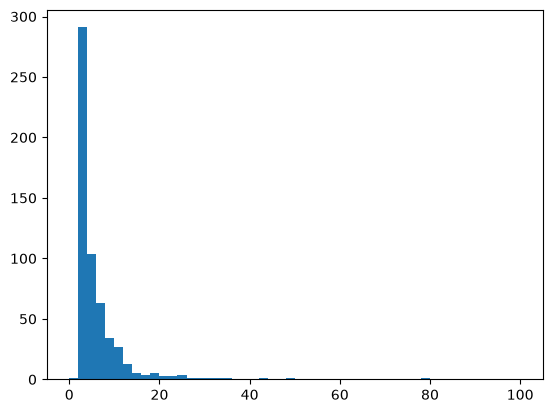

In [48]:
removal_counts, large_removal_indices = compare_samples(samples, scrubbed_samples)

plt.hist(removal_counts, bins=50, range=(0, 100))
plt.show()

In [49]:
print("Number of samples with large strokes removed: ", len(large_removal_indices))
print("Flagged samples: ", large_removal_indices)

Number of samples with large strokes removed:  18
Flagged samples:  [566, 776, 793, 832, 1176, 1437, 2373, 2593, 3213, 3381, 3420, 3461, 3916, 3917, 3923, 4596, 4856, 4994]


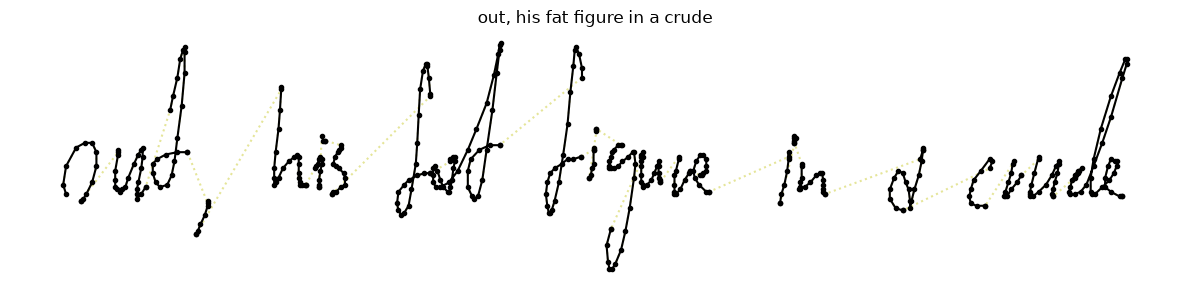

In [71]:
# Inspect the flagged samples

idx = 2373

draw_points(scrubbed_samples[idx], label=texts[idx])

As mentioned before we can also correct the global slant of the handwriting using some alignment maths!

In [55]:
# Correct the global slant of a handwritten line.

# Taken from: 

# https://github.com/rudyoactiv/typescribe-handwriting/blob/master/handwriting_synthesis/drawing/operations.py#L44

def _align(xy: np.ndarray) -> np.ndarray:
    xy = np.copy(xy)
    x, y = xy[:, 0].reshape(-1, 1), xy[:, 1].reshape(-1, 1)
    design = np.concatenate([np.ones([x.shape[0], 1]), x], axis=1)
    offset, slope = np.linalg.inv(design.T.dot(design)).dot(design.T).dot(y).squeeze()
    theta = np.arctan(slope)
    rotation = np.array(
        [[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]
    )
    return np.dot(xy, rotation) - offset


def align_points(points: list[Point]) -> list[Point]:
    point_array = np.array(
        [[point.x, point.y] for point in points], dtype=np.float32
    )
    aligned_points = _align(point_array)

    return [
        Point(x=float(array[0]), y=float(array[1]), pen_up=point.pen_up)
        for array, point in zip(aligned_points, points)
    ] 

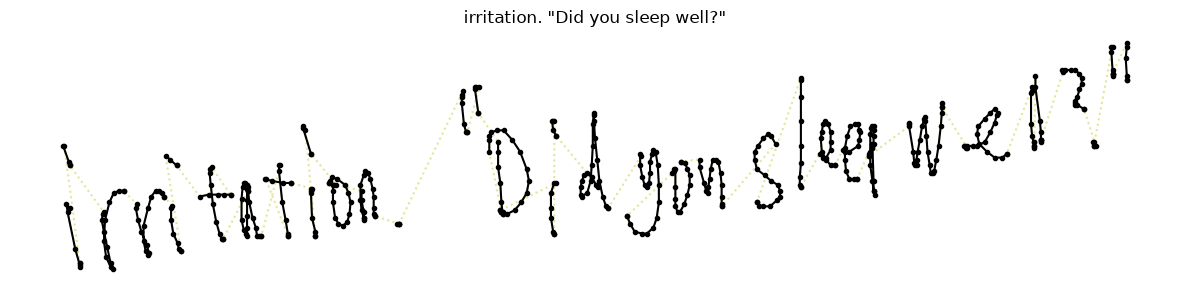

In [58]:
# before point alignment
idx = 419

draw_points(scrubbed_samples[idx], label=texts[idx])

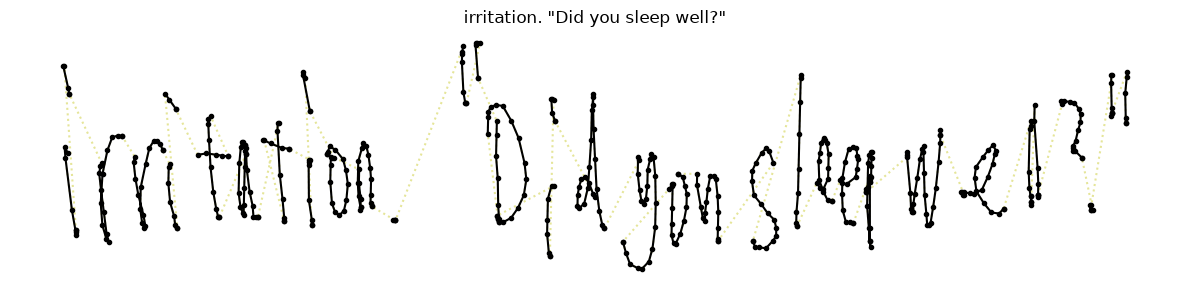

In [59]:
# after point alignment

draw_points(align_points(scrubbed_samples[idx]), label=texts[idx])

Great, let's wrap both the artifact removal and alignment functions into one, and apply it to our dataset!

In [60]:
# Samples flagged above whose removed stroke is real handwriting, so the cleaned strokes
# would no longer match the text. 3213 wraps "his" onto a second line.

DROP_INDEXES = set([3213])
# DROP_INDEXES = set()

def clean_samples(samples: list[list[Point]], texts: list[str]) -> tuple[list[list[Point]], list[str]]:
    
    cleaned_samples, cleaned_texts = [], []

    for idx, (points, text) in enumerate(zip(samples, texts)):

        if idx in DROP_INDEXES:
            continue

        filtered_points = remove_artifacts(points)
        if not filtered_points:
            continue

        cleaned_samples.append(align_points(filtered_points))
        cleaned_texts.append(text)

    return cleaned_samples, cleaned_texts

In [61]:
clean_samples, clean_texts = clean_samples(samples, texts)

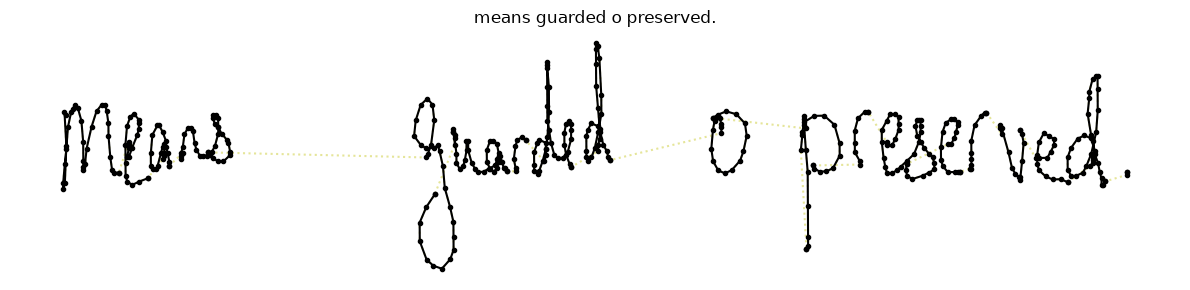

In [62]:
idx = 4072

draw_points(clean_samples[idx], label=clean_texts[idx])

# Save Data

The data is finally ready for training! Let's create a checkpoint here allowing us to load the cleaned data.

There are one or a few things that still need to be done on the model side of things in order to get it working - Text Vectorisation, normalization, shuffling, splitting, etc. - but our cleaning work here is done! 🎉

In [63]:
strokes_data = [calculate_strokes(sample) for sample in clean_samples]

In [64]:
# Let's confirm if all strokes end with a SOS and an EOS token

sos = np.array([0, 0, 1, 0, 0], dtype=np.float32)
eos = np.array(eos_token, dtype=np.float32)

assert all((strokes[0] == sos).all() and (strokes[-1] == eos).all() for strokes in strokes_data)

In [65]:
SAVE_DIR = DATA_DIR / "cleaned" / (DATASET + '-' + datetime.now().strftime("%Y-%m-%dT%H-%M-%S"))
SAVE_DIR.mkdir()

In [66]:
# Save the stroke data

np.savez(SAVE_DIR / "strokes_data.npz", *strokes_data)

In [67]:
# Save the texts

with open(SAVE_DIR / "texts.json", 'w', encoding='utf-8') as f:
    json.dump(clean_texts, f, ensure_ascii=False, separators=(',', ':'))